In [1]:
from DynamicPortfolioOptimizationFunc import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import genpareto
from arch import arch_model
import yfinance as yf
import warnings
import warnings

#### Functions

In [2]:
 # Suppress the "Scale" warnings from arch_model so we can run raw data cleanly
warnings.filterwarnings("ignore")

def calibrate_regimes_direct(vol_models, threshold=3.0, focus_quantile=0.1, label="Asset"):
    """
    Calibrates Pareto parameters but PRIORITIZES the worst 'focus_quantile' (e.g., 10%)
    to ensure the model captures the massive crashes.
    """
    pooled_z = []

    # 1. Extract Residuals (Same as before)
    for ticker, res in vol_models.items():
        z = res.std_resid.dropna()
        pooled_z.extend(z.values)

    pooled_z = np.array(pooled_z)
    total_obs = len(pooled_z)

    if total_obs == 0: return None # Safety
    jumps = pooled_z[np.abs(pooled_z) > threshold]
    if len(jumps) == 0: return None # Safety

    crashes = jumps[jumps < 0]
    rallies = jumps[jumps > 0]

    # --- HELPER: The Tail-Focused Logic ---
    def fit_with_focus(data_array, base_thresh, quantile):
        # data_array is the magnitude (absolute value)

        # A. Find the "Nightmare Line" (e.g., the worst 10% of the jumps)
        # quantile=0.10 means we look at the top 10% of magnitude
        if len(data_array) < 10:
            return genpareto.fit(data_array - base_thresh, floc=0)

        extreme_thresh = np.quantile(data_array, 1 - quantile)

        # B. Isolate the Monsters
        monsters = data_array[data_array >= extreme_thresh]

        # C. Fit Shape (c) ONLY on the monsters
        # This decides "How fat is the tail?" based only on the worst events
        c_extreme, _, _ = genpareto.fit(monsters - extreme_thresh, floc=0)

        # Safety: If shape is negative (thin tail), force it to 0 (exponential)
        if c_extreme < 0: c_extreme = 0

        # D. Fit Scale on the FULL set, but holding Shape constant
        # This ensures the curve starts at the right height (3 sigma) but decays at the "monster" rate
        _, _, scale_final = genpareto.fit(data_array - base_thresh, fc=c_extreme, floc=0)

        return c_extreme, 0, scale_final

    # 2. Fit Parameters using the Helper
    # Crash Fit
    if len(crashes) > 0:
        c_crash, _, scale_crash = fit_with_focus(np.abs(crashes), threshold, quantile=focus_quantile)
        prob_crash = len(crashes) / len(jumps)
    else:
        c_crash, scale_crash, prob_crash = 0.1, 1.0, 0.5

    # Rally Fit
    if len(rallies) > 0:
        c_rally, _, scale_rally = fit_with_focus(np.abs(rallies), threshold, quantile=focus_quantile)
        prob_rally = len(rallies) / len(jumps)
    else:
        c_rally, scale_rally, prob_rally = 0.1, 1.0, 0.5

    lambda_param = len(jumps) / total_obs

    return {
        "label": label,
        "lambda": lambda_param,
        "threshold": threshold,
        "prob_crash": prob_crash,
        "crash_params": (c_crash, scale_crash),
        "rally_params": (c_rally, scale_rally),
        "data": {"crashes": crashes, "rallies": rallies, "total_count": len(jumps)}
    }

# --- 2. PLOTTING FUNCTION ---
def plot_regimes_side_by_side(sys_result, idio_result):
    if sys_result is None and idio_result is None: return

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    plt.style.use('dark_background')

    # Handle cases where one might be None
    results = []
    if sys_result: results.append(sys_result)
    if idio_result: results.append(idio_result)

    titles = [r['label'] for r in results]

    for i, res in enumerate(results):
        ax = axes[i] if len(results) > 1 else axes
        thresh = res['threshold']
        total = res['data']['total_count']

        crashes = res['data']['crashes']
        rallies = res['data']['rallies']

        # Weights
        w_c = np.ones_like(crashes) / total if len(crashes) > 0 else []
        w_r = np.ones_like(rallies) / total if len(rallies) > 0 else []

        bins = np.linspace(-20, 20, 100)
        bin_width = bins[1] - bins[0]

        # Histograms
        if len(crashes) > 0:
            ax.hist(crashes, bins=bins, weights=w_c, color='#D00000', alpha=0.8, label='Crashes', edgecolor='black')
        if len(rallies) > 0:
            ax.hist(rallies, bins=bins, weights=w_r, color='#008000', alpha=0.8, label='Rallies', edgecolor='black')

        # Models
        c_c, s_c = res['crash_params']
        x_c = np.linspace(-20, -thresh, 200)
        pdf_c = genpareto.pdf(np.abs(x_c)-thresh, c_c, loc=0, scale=s_c)
        ax.plot(x_c, pdf_c * res['prob_crash'] * bin_width, 'w--', linewidth=2.5, label=f'Shape={c_c:.2f}')

        c_r, s_r = res['rally_params']
        x_r = np.linspace(thresh, 20, 200)
        pdf_r = genpareto.pdf(x_r-thresh, c_r, loc=0, scale=s_r)
        ax.plot(x_r, pdf_r * (1-res['prob_crash']) * bin_width, 'w--', linewidth=2.5)

        ax.set_title(res['label'], fontsize=16, fontweight='bold', color='white', pad=15)
        ax.set_xlabel("Jump Size (Z-Score)", color='white')
        ax.text(0.05, 0.95, f"Freq ($\lambda$): {res['lambda']:.2%}", transform=ax.transAxes, color='yellow', fontsize=12, fontweight='bold', va='top')

        ax.axvspan(-thresh, thresh, color='gray', alpha=0.15)
        ax.legend(loc='upper right', frameon=True, facecolor='black')
        ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

<>:128: SyntaxWarning: invalid escape sequence '\l'
<>:128: SyntaxWarning: invalid escape sequence '\l'
~\AppData\Local\Temp\ipykernel_59952\480767368.py:128: SyntaxWarning: invalid escape sequence '\l'
  ax.text(0.05, 0.95, f"Freq ($\lambda$): {res['lambda']:.2%}", transform=ax.transAxes, color='yellow', fontsize=12, fontweight='bold', va='top')


# Systematic Jump Section

In [3]:
# Data Retrieval
snp_500 = ["^GSPC"]
spx_returns = ret_df(snp_500,period="80y",interval="1d")
spx_returns = spx_returns.dropna()
spx_returns = spx_returns*100

In [4]:
# Volatility modeling
spx_vol_model = arch_model(spx_returns,mean="AR",vol="GARCH")
spx_res = spx_vol_model.fit(update_freq=5)
# Jump estimation function comes from portfolio functions so it needs a dictionary
ticker_name = spx_returns.columns[0]
vol_models_dict = {ticker_name: spx_res}

Iteration:      5,   Func. Count:     38,   Neg. LLF: 24661.901836038956
Iteration:     10,   Func. Count:     67,   Neg. LLF: 24645.004973674644
Optimization terminated successfully    (Exit mode 0)
            Current function value: 24645.004973674644
            Iterations: 11
            Function evaluations: 71
            Gradient evaluations: 11


#### Jump Visualization Function

In [5]:
def plot_jump_distribution(returns, vol_models, jump_threshold=3.0):
    """
    Extracts jumps using the same logic as estimate_jump_parameters
    and plots them in a histogram with a fitted normal curve.
    """
    all_jump_returns = []

    # Handle the case where vol_models is a single object (fix for your previous error)
    if not isinstance(vol_models, dict):
        # Assuming returns is a DataFrame, use its first column name
        vol_models = {returns.columns[0]: vol_models}

    for stock in returns.columns:
        # 1. Get standardized residuals
        if stock not in vol_models:
            continue

        res = vol_models[stock]

        # Standardize returns by conditional volatility
        # We align the length using -len() to handle any potential data mismatch
        cond_vol = res.conditional_volatility
        raw_rets = returns[stock].iloc[-len(cond_vol):].values

        standardized_residuals = raw_rets / cond_vol.values

        # 2. Identify jumps
        jumps_mask = np.abs(standardized_residuals) > jump_threshold

        # 3. Extract the actual return values for those jumps
        jump_vals = raw_rets[jumps_mask]
        all_jump_returns.extend(jump_vals)

    all_jump_returns = np.array(all_jump_returns)

    if len(all_jump_returns) == 0:
        print("No jumps found to plot.")
        return

    # --- Plotting Code ---
    plt.figure(figsize=(10, 6))

    # Histogram of Jumps
    # 'bins=30' gives a good shape; 'density=True' allows us to overlay the curve
    plt.hist(all_jump_returns, bins=100, color='#4c72b0', edgecolor='black', alpha=0.7, density=True, label='Observed Jumps')

    # Overlay Normal Distribution (Red Line)
    # This helps you see if your jumps are "normal" or skewed
    mu, std = norm.fit(all_jump_returns)
    xmin, xmax = plt.xlim()
    x = np.linspace(xmin, xmax, 100)
    p = norm.pdf(x, mu, std)
    plt.plot(x, p, 'r--', linewidth=2, label=f'Normal Fit\n($\mu$={mu:.2f}, $\sigma$={std:.2f})')

    # Formatting
    plt.title(f'Distribution of Identified Jumps (> {jump_threshold}$\sigma$)', fontsize=14)
    plt.xlabel('Jump Return Size', fontsize=12)
    plt.ylabel('Density', fontsize=12)
    plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
    plt.legend()
    plt.grid(axis='y', alpha=0.3)

#### Jump Estimation

Found 164 jumps across all assets.
0.008150688335569803
-1.6984337711019568
3.6687030753013588


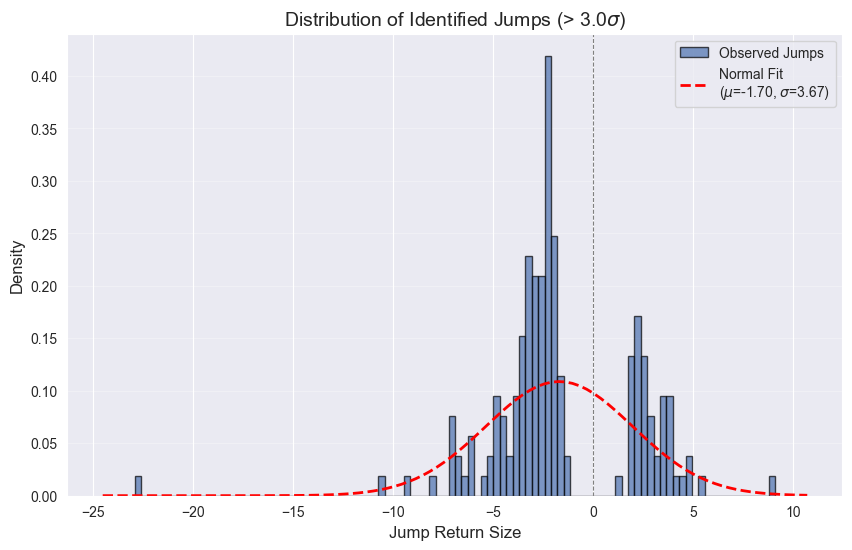

In [6]:
# Jump Analysis, systematic
systematic_lambda, systematic_mu, systematic_sigma = estimate_jump_parameters(returns=spx_returns,vol_models=vol_models_dict,jump_threshold=3)

print(systematic_lambda)
print(systematic_mu)
print(systematic_sigma)
plot_jump_distribution(returns=spx_returns, vol_models=vol_models_dict, jump_threshold=3.0)

1. Downloading Data for 447 assets...


[*********************100%***********************]  439 of 439 completed

29 Failed downloads:
['DFS', 'ABC', 'WLL', 'WRK', 'JCPNQ', 'PKI', 'RE', 'SHLDQ', 'PARA', 'HES', 'IDMCQ', 'HTZQ', 'CHKAQ', 'MRO', 'UALGQ', 'ANSS', 'PEAK', 'CITGQ', 'ATVI', 'WLTW', 'GMGMQ']: YFTzMissingError('possibly delisted; no timezone found')
['ADELQ', 'LEHMQ', 'GBLXQ', 'WAMUQ', 'ENRNQ', 'BSC', 'TOY', 'WCOEQ']: YFPricesMissingError('possibly delisted; no price data found  (1d 1927-02-12 -> 2026-01-18)')



2. Fitting GARCH Models on 410 valid tickers...
   (This will take 5-10 minutes.)


~\PycharmProjects\PythonProject\.venv\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(


~\PycharmProjects\PythonProject\.venv\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
~\PycharmProjects\PythonProject\.venv\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(


...

~\PycharmProjects\PythonProject\.venv\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(


~\PycharmProjects\PythonProject\.venv\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(


~\PycharmProjects\PythonProject\.venv\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(


~\PycharmProjects\PythonProject\.venv\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
~\PycharmProjects\PythonProject\.venv\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
~\PycharmProjects\PythonProject\.venv\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(
~\PycharmProjects\PythonProject\.venv\Lib\site-packages\arch\univariate\base.py:768: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

 

   Progress: 400/410 | Fitted: 392 | Skipped(<10y): 9...
   >> COMPLETED. Final Count: 401 assets modeled.
   >> Skipped 9 stocks (listing history < 10 years).
   >> Failed fits: 0

3. Calibrating Regimes...


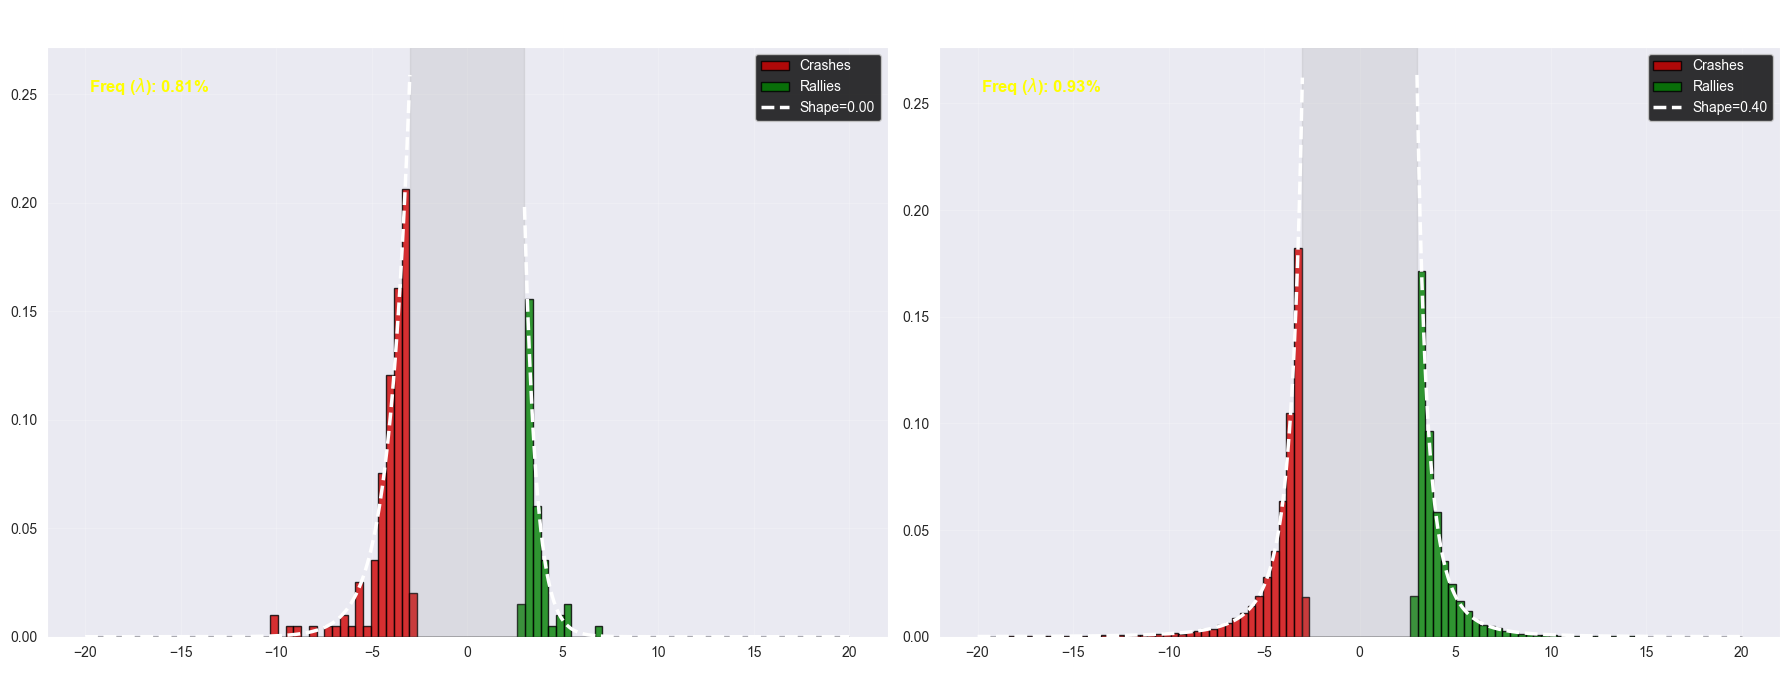


--- FINAL JUMP PARAMETERS (S&P 500 Full Universe) ---
{'systematic': {'lambda': 0.008080561984813417, 'prob_crash': 0.6984924623115578, 'crash_shape': 0, 'crash_scale': np.float64(1.0905273437500003), 'rally_shape': 0, 'rally_scale': np.float64(0.6153320312499997), 'threshold': 3.0}, 'idiosyncratic': {'lambda': 0.0092885413710509, 'prob_crash': 0.5303980869320579, 'crash_shape': np.float64(0.3955326485117717), 'crash_scale': np.float64(0.8176757812499998), 'rally_shape': np.float64(0.3691758762437959), 'rally_scale': np.float64(0.7205078124999997), 'threshold': 3.0}}


In [7]:
systematic_ticker = ["^GSPC"]
# --- THE "CENTURION" POOL (100+ Diverse Assets) ---
idiosyncratic_tickers = [
    # --- MATERIALS & CHEMICALS ---
    "LIN", "SHW", "APD", "ECL", "FCX", "NEM", "DOW", "DD", "CTVA", "PPG", "NUE", "VMC", "MLM", "ALB", "FMC", "EMN", "CF", "MOS", "IFF", "CE", "BALL", "PKG", "IP", "WRK", "AVY", "AMCR", "SEE",
    # --- INDUSTRIALS ---
    "GE", "CAT", "DE", "HON", "UNP", "UPS", "RTX", "BA", "LMT", "ETN", "ADP", "ITW", "WM", "CSX", "NSC", "GD", "EMR", "FDX", "PH", "CTAS", "PCAR", "CMI", "TDG", "NOC", "ROP", "TT", "CARR", "OTIS", "FAST", "AME", "EFX", "VRSK", "ODFL", "GWW", "ROK", "CPRT", "URI", "PWR", "EXPD", "RSG", "WAB", "DOV", "XYL", "SWK", "MAS", "SNA", "TXT", "HII", "LUV", "DAL", "UAL", "AAL", "ALK", "CHRW", "J",
    # --- CONSUMER DISCRETIONARY ---
    "AMZN", "TSLA", "HD", "MCD", "NKE", "LOW", "SBUX", "BKNG", "TJX", "TGT", "MAR", "ORLY", "CMG", "F", "GM", "HLT", "ROST", "AZO", "YUM", "LVS", "TSCO", "APTV", "DHI", "LEN", "GPC", "EBAY", "EXPE", "ULTA", "KMX", "RCL", "CCL", "NCLH", "BBY", "GRMN", "DRI", "HAS", "MGM", "WYNN", "PHM", "VFC", "RL", "TPR", "PVH", "LKQ", "POOL", "MHK", "BWA", "HOG", "NWL",
    # --- CONSUMER STAPLES ---
    "PG", "COST", "WMT", "KO", "PEP", "PM", "MDLZ", "MO", "CL", "TGT", "EL", "KMB", "GIS", "SYY", "STZ", "ADM", "HSY", "K", "MKC", "CLX", "KHC", "TSN", "CAG", "CHD", "HRL", "SJM", "CPB", "TAP", "LW", "BG", "IPG", "OMC",
    # --- HEALTH CARE ---
    "LLY", "UNH", "JNJ", "MRK", "ABBV", "TMO", "ABT", "PFE", "AMGN", "DHR", "ISRG", "ELV", "SYK", "BMY", "GILD", "CVS", "CI", "VRTX", "ZTS", "BDX", "REGN", "BSX", "HCA", "HUM", "EW", "MCK", "CNC", "IQV", "A", "DXCM", "MTD", "RMD", "IDXX", "BIO", "TFX", "COO", "HOLX", "STE", "WAT", "PKI", "DGX", "LH", "ALGN", "XRAY", "UHS", "INCY", "BIIB", "BAX", "CAH", "ABC", "HSIC",
    # --- FINANCIALS ---
    "BRK-B", "JPM", "V", "MA", "BAC", "WFC", "MS", "GS", "SCHW", "AXP", "BLK", "SPGI", "C", "PGR", "CB", "MMC", "MCO", "USB", "PNC", "TFC", "ICE", "CME", "AON", "BK", "TRV", "AIG", "COF", "MET", "ALL", "PRU", "STT", "HIG", "AFL", "DFS", "FITB", "MTB", "WTW", "AMP", "NTRS", "KEY", "CFG", "HBAN", "RF", "CINF", "PFG", "RJF", "L", "GL", "AIZ", "WRB", "BRO", "AJG", "WLTW", "MKTX", "NDAQ", "CBOE", "RE", "IVZ", "BEN",
    # --- INFORMATION TECHNOLOGY ---
    "AAPL", "MSFT", "NVDA", "AVGO", "GOOGL", "GOOG", "META", "CRM", "ADBE", "CSCO", "AMD", "ACN", "TXN", "INTC", "QCOM", "IBM", "AMAT", "NOW", "LRCX", "ADI", "MU", "PANW", "SNPS", "KLAC", "CDNS", "ROP", "NXPI", "APH", "TEL", "MSI", "MCHP", "IT", "ANSS", "GLW", "HPQ", "HPE", "KEYS", "FTNT", "STX", "WDC", "NTAP", "CDW", "BR", "TYL", "PTC", "AKAM", "GEN", "QRVO", "SWKS", "TRMB", "TER", "ZBRA", "FFIV",
    # --- COMMUNICATION SERVICES ---
    "GOOGL", "GOOG", "META", "NFLX", "DIS", "T", "VZ", "CMCSA", "TMUS", "CHTR", "ATVI", "EA", "TTWO", "WBD", "OMC", "IPG", "LYV", "PARA", "FOXA", "FOX", "NWSA", "NWS",
    # --- UTILITIES ---
    "NEE", "SO", "DUK", "SRE", "AEP", "D", "PEG", "EXC", "XEL", "ED", "ES", "EIX", "WEC", "DTE", "ETR", "PPL", "AEE", "CMS", "CNP", "ATO", "LNT", "EVRG", "FE", "AWK", "AES", "NRG", "NI", "PNW",
    # --- REAL ESTATE ---
    "PLD", "AMT", "EQIX", "CCI", "PSA", "O", "SPG", "DLR", "VICI", "WELL", "AVB", "EQR", "CSGP", "SBAC", "EXR", "CBRE", "WY", "ARE", "VTR", "BXP", "HST", "MAA", "UDR", "IRM", "REG", "ESS", "KIM", "PEAK", "FRT",
    # --- ENERGY ---
    "XOM", "CVX", "COP", "SLB", "EOG", "MPC", "PSX", "VLO", "OXY", "WMB", "HES", "KMI", "HAL", "BKR", "DVN", "OKE", "TRGP", "CTRA", "MRO", "FANG", "APA", "EQT",

    # Bankrupt

# 2008 GFC Jump Regime
    "LEHMQ",   # Lehman Brothers
    "WAMUQ",   # Washington Mutual
    "GMGMQ",   # General Motors (Old stock)
    "CITGQ",   # CIT Group
    "IDMCQ",   # IndyMac Bank
    "AIG",     # AIG (Survived, but extreme jump sensitivity)
    "BSC",     # Bear Stearns
    "MER",     # Merrill Lynch (Acquired during crash)

    # 2000-2002 Dot-Com/Telecom Regime
    "WCOEQ",   # WorldCom
    "ENRNQ",   # Enron
    "GBLXQ",   # Global Crossing
    "ADELQ",   # Adelphia
    "UALGQ",   # United Airlines (2002 filing)

    # 2017-2023 Retail & Energy Regimes
    "SHLDQ",   # Sears
    "TOY",     # Toys "R" Us (Data may be spotty/private)
    "CHKAQ",   # Chesapeake Energy
    "HTZQ",    # Hertz (2020 filing)
    "JCPNQ",   # J.C. Penney
    "WLL",     # Whiting Petroleum
    "YELLQ"    # Yellow Corp (2023)
]

print(f"1. Downloading Data for {len(idiosyncratic_tickers)} assets...")

# Systematic
sys_data = yf.download(systematic_ticker, period="max", interval="1d", progress=False, auto_adjust=True)['Close']
sys_returns = np.log(sys_data / sys_data.shift(1)).dropna()

# Idiosyncratic (Batch Download)
# Note: yfinance handles 500 tickers well, but it might take 30-60 seconds.
try:
    idio_data = yf.download(idiosyncratic_tickers, period="max", interval="1d", progress=True, auto_adjust=True)['Close']
except Exception as e:
    print(f"[!] Batch download failed: {e}")
    idio_data = pd.DataFrame()

# Clean Data
idio_data = idio_data.dropna(axis=1, how='all')
idio_returns = np.log(idio_data / idio_data.shift(1)).dropna(how='all')

# C. GARCH FITTING (Massive Loop)
print(f"\n2. Fitting GARCH Models on {len(idio_returns.columns)} valid tickers...")
print("   (This will take 5-10 minutes.)")

sys_vol_models = {}
sys_series = sys_returns if isinstance(sys_returns, pd.Series) else sys_returns.iloc[:, 0]
am = arch_model(sys_series, mean="AR", vol="GARCH")
sys_vol_models[systematic_ticker[0]] = am.fit(disp="off")

idio_vol_models = {}
if isinstance(idio_returns, pd.Series): idio_returns = idio_returns.to_frame()

count = 0
skipped_short = 0
skipped_error = 0
total_tickers = len(idio_returns.columns)

for i, t in enumerate(idio_returns.columns):
    series = idio_returns[t].dropna()

    # FILTER: STRICT 10-YEAR CHECK (approx 2400 trading days)
    if len(series) < 2400:
        skipped_short += 1
        continue

    try:
        # Fit GARCH
        am = arch_model(series, mean="AR", vol="GARCH")
        res = am.fit(disp="off")
        idio_vol_models[t] = res
        count += 1
    except:
        skipped_error += 1

    # Progress Update every 20 stocks
    if i % 20 == 0:
        print(f"   Progress: {i}/{total_tickers} | Fitted: {count} | Skipped(<10y): {skipped_short}...", end='\r')

print(f"\n   >> COMPLETED. Final Count: {count} assets modeled.")
print(f"   >> Skipped {skipped_short} stocks (listing history < 10 years).")
print(f"   >> Failed fits: {skipped_error}")

# D. CALIBRATION
print("\n3. Calibrating Regimes...")
sys_res = calibrate_regimes_direct(sys_vol_models, threshold=3.0, label="SYSTEMATIC (S&P 500)")
idio_res = calibrate_regimes_direct(idio_vol_models, threshold=3.0, label=f"IDIOSYNCRATIC (Pooled n={count})")

# E. OUTPUT
plot_regimes_side_by_side(sys_res, idio_res)

if sys_res and idio_res:
    JUMP_CONFIG = {
        "systematic": {
            "lambda": sys_res['lambda'],
            "prob_crash": sys_res['prob_crash'],
            "crash_shape": sys_res['crash_params'][0],
            "crash_scale": sys_res['crash_params'][1],
            "rally_shape": sys_res['rally_params'][0],
            "rally_scale": sys_res['rally_params'][1],
            "threshold": sys_res['threshold']
        },
        "idiosyncratic": {
            "lambda": idio_res['lambda'],
            "prob_crash": idio_res['prob_crash'],
            "crash_shape": idio_res['crash_params'][0],
            "crash_scale": idio_res['crash_params'][1],
            "rally_shape": idio_res['rally_params'][0],
            "rally_scale": idio_res['rally_params'][1],
            "threshold": idio_res['threshold']
        }
    }
    print("\n--- FINAL JUMP PARAMETERS (S&P 500 Full Universe) ---")
    print(JUMP_CONFIG)
else:
    print("Calibration failed.")

# Are crashes beta sensitive?

1. Downloading Data...
   >> Fetching Benchmark (^GSPC)...
   >> Fetching 447 Assets...



29 Failed downloads:
['DFS', 'ABC', 'WLL', 'WRK', 'PKI', 'JCPNQ', 'RE', 'SHLDQ', 'PARA', 'HES', 'HTZQ', 'IDMCQ', 'CHKAQ', 'MRO', 'UALGQ', 'ANSS', 'PEAK', 'CITGQ', 'ATVI', 'WLTW', 'GMGMQ']: YFPricesMissingError('possibly delisted; no price data found  (period=10y) (Yahoo error = "No data found, symbol may be delisted")')
['ADELQ', 'LEHMQ', 'GBLXQ', 'WAMUQ', 'ENRNQ', 'BSC', 'TOY', 'WCOEQ']: YFPricesMissingError('possibly delisted; no price data found  (period=10y)')


2. Calculating Betas (Crash & Rally Sensitivity)...
   >> Benchmark Range: 2016-01-20 to 2026-01-16
   >> Benchmark Volatility (Daily): 0.0114
   >> Found 46 Systematic Crash Days (Threshold: -2.5 sigma)
   >> Found 21 Systematic Rally Days (Threshold: +2.5 sigma)

--- TOP DOUBLE TRAPS (Worst Negative Convexity) ---
    Ticker  Normal_Beta  Crash_Liar_Ratio  Rally_Ratio
358   TRGP     1.410470          1.384316     0.419552
31     APA     1.586976          1.343439     0.540691
282    OKE     1.256526          1.337753     0.622301
149   FANG     1.259628          1.293242     0.664348
286    OXY     1.280854          1.318890     0.748544
122    DVN     1.425727          1.200282     0.656586
405  YELLQ     1.696540          1.032429     0.533861
335    SPG     1.136661          1.203804     0.724278
331    SLB     1.154973          1.223569     0.763735
261   NCLH     1.805337          1.224438     0.774466

--- ZONE STATISTICS ---

Low Beta Stocks (< 1.0) (Total: 220)
  [DOWNSIDE] C

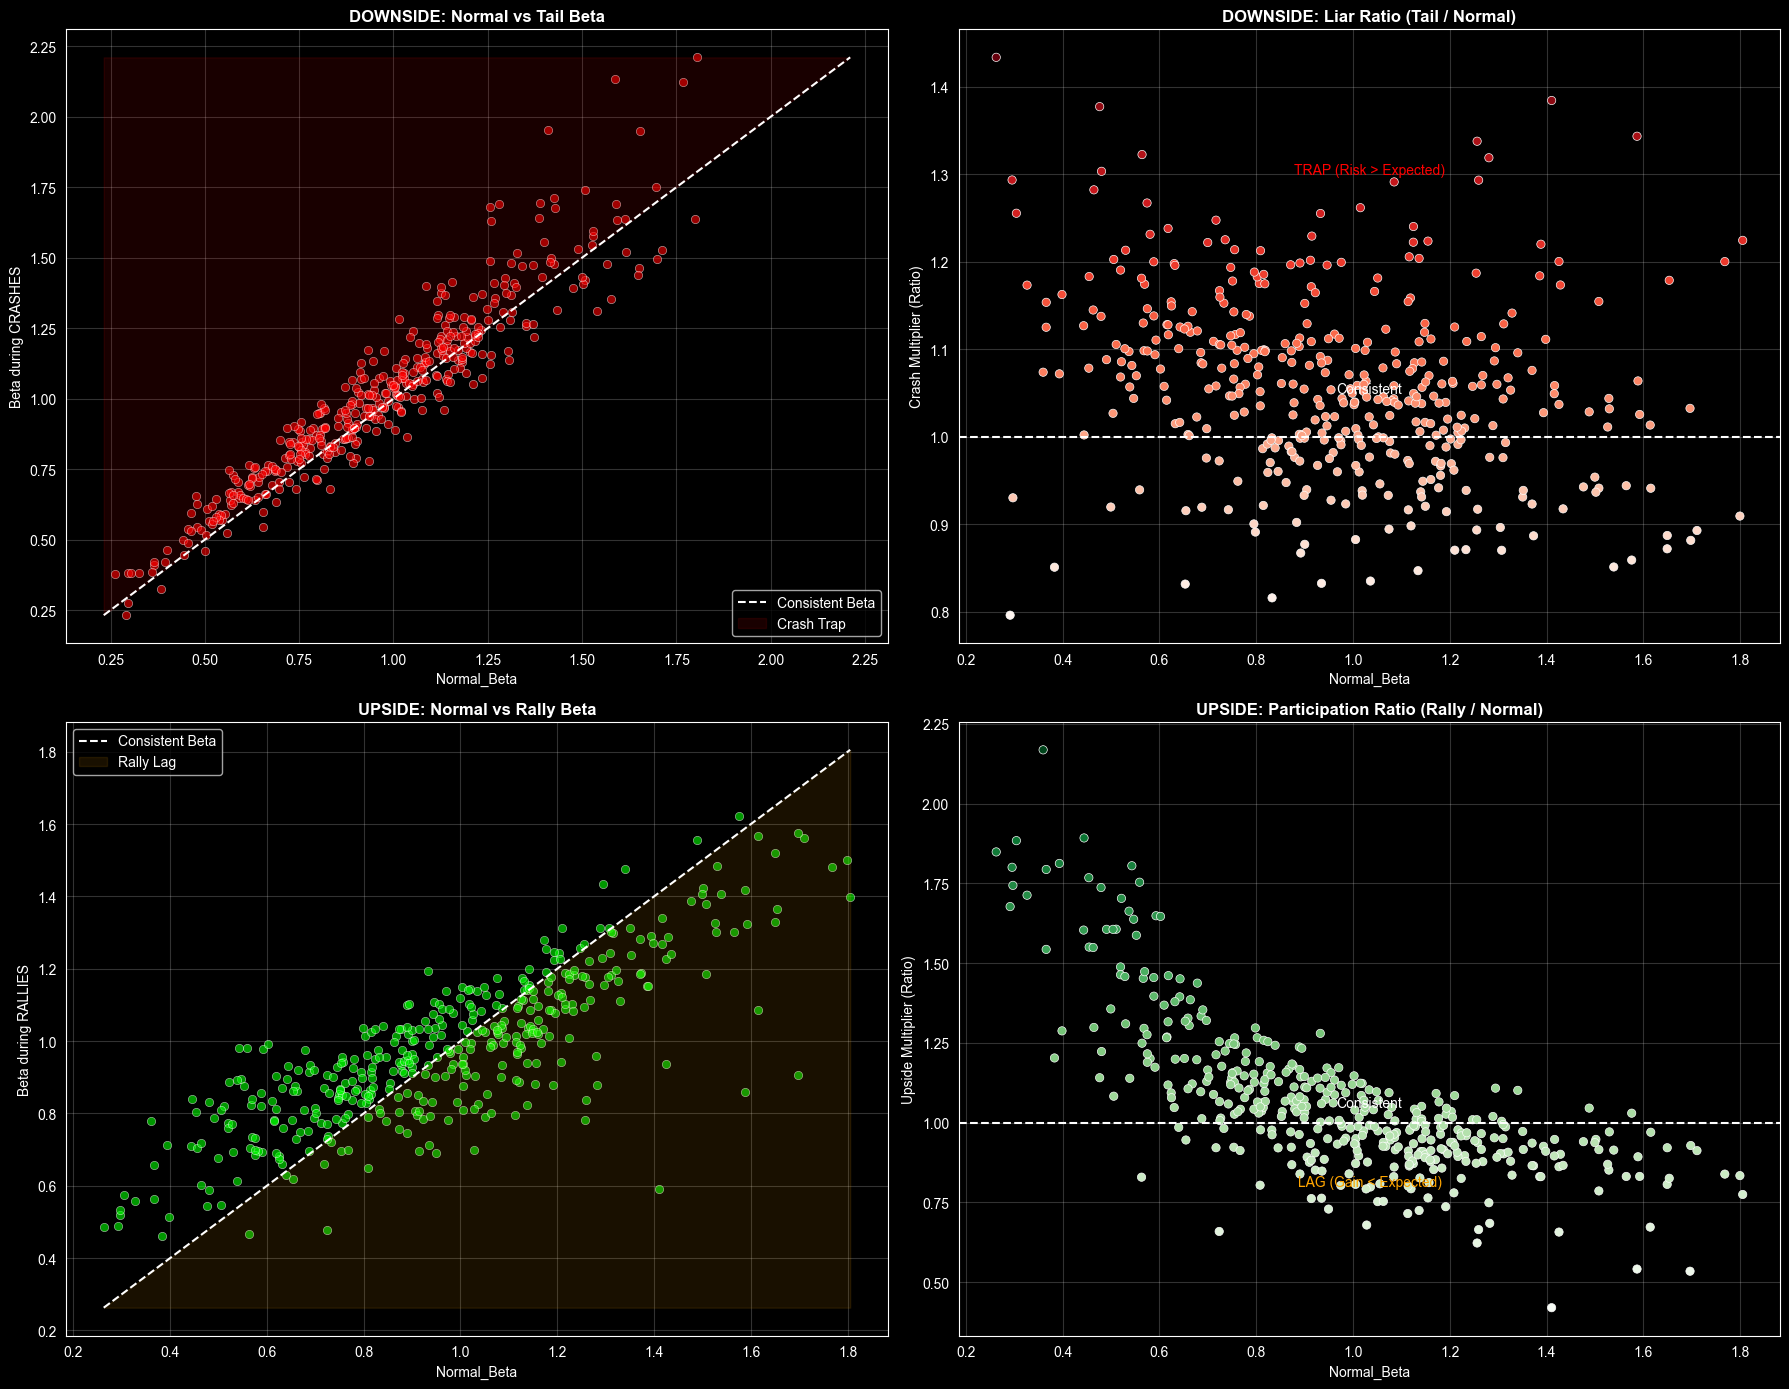

In [8]:
#Beta sensitivity in crash

TICKERS = [
    # --- MATERIALS & CHEMICALS ---
    "LIN", "SHW", "APD", "ECL", "FCX", "NEM", "DOW", "DD", "CTVA", "PPG", "NUE", "VMC", "MLM", "ALB", "FMC", "EMN", "CF", "MOS", "IFF", "CE", "BALL", "PKG", "IP", "WRK", "AVY", "AMCR", "SEE",
    # --- INDUSTRIALS ---
    "GE", "CAT", "DE", "HON", "UNP", "UPS", "RTX", "BA", "LMT", "ETN", "ADP", "ITW", "WM", "CSX", "NSC", "GD", "EMR", "FDX", "PH", "CTAS", "PCAR", "CMI", "TDG", "NOC", "ROP", "TT", "CARR", "OTIS", "FAST", "AME", "EFX", "VRSK", "ODFL", "GWW", "ROK", "CPRT", "URI", "PWR", "EXPD", "RSG", "WAB", "DOV", "XYL", "SWK", "MAS", "SNA", "TXT", "HII", "LUV", "DAL", "UAL", "AAL", "ALK", "CHRW", "J",
    # --- CONSUMER DISCRETIONARY ---
    "AMZN", "TSLA", "HD", "MCD", "NKE", "LOW", "SBUX", "BKNG", "TJX", "TGT", "MAR", "ORLY", "CMG", "F", "GM", "HLT", "ROST", "AZO", "YUM", "LVS", "TSCO", "APTV", "DHI", "LEN", "GPC", "EBAY", "EXPE", "ULTA", "KMX", "RCL", "CCL", "NCLH", "BBY", "GRMN", "DRI", "HAS", "MGM", "WYNN", "PHM", "VFC", "RL", "TPR", "PVH", "LKQ", "POOL", "MHK", "BWA", "HOG", "NWL",
    # --- CONSUMER STAPLES ---
    "PG", "COST", "WMT", "KO", "PEP", "PM", "MDLZ", "MO", "CL", "TGT", "EL", "KMB", "GIS", "SYY", "STZ", "ADM", "HSY", "K", "MKC", "CLX", "KHC", "TSN", "CAG", "CHD", "HRL", "SJM", "CPB", "TAP", "LW", "BG", "IPG", "OMC",
    # --- HEALTH CARE ---
    "LLY", "UNH", "JNJ", "MRK", "ABBV", "TMO", "ABT", "PFE", "AMGN", "DHR", "ISRG", "ELV", "SYK", "BMY", "GILD", "CVS", "CI", "VRTX", "ZTS", "BDX", "REGN", "BSX", "HCA", "HUM", "EW", "MCK", "CNC", "IQV", "A", "DXCM", "MTD", "RMD", "IDXX", "BIO", "TFX", "COO", "HOLX", "STE", "WAT", "PKI", "DGX", "LH", "ALGN", "XRAY", "UHS", "INCY", "BIIB", "BAX", "CAH", "ABC", "HSIC",
    # --- FINANCIALS ---
    "BRK-B", "JPM", "V", "MA", "BAC", "WFC", "MS", "GS", "SCHW", "AXP", "BLK", "SPGI", "C", "PGR", "CB", "MMC", "MCO", "USB", "PNC", "TFC", "ICE", "CME", "AON", "BK", "TRV", "AIG", "COF", "MET", "ALL", "PRU", "STT", "HIG", "AFL", "DFS", "FITB", "MTB", "WTW", "AMP", "NTRS", "KEY", "CFG", "HBAN", "RF", "CINF", "PFG", "RJF", "L", "GL", "AIZ", "WRB", "BRO", "AJG", "WLTW", "MKTX", "NDAQ", "CBOE", "RE", "IVZ", "BEN",
    # --- INFORMATION TECHNOLOGY ---
    "AAPL", "MSFT", "NVDA", "AVGO", "GOOGL", "GOOG", "META", "CRM", "ADBE", "CSCO", "AMD", "ACN", "TXN", "INTC", "QCOM", "IBM", "AMAT", "NOW", "LRCX", "ADI", "MU", "PANW", "SNPS", "KLAC", "CDNS", "ROP", "NXPI", "APH", "TEL", "MSI", "MCHP", "IT", "ANSS", "GLW", "HPQ", "HPE", "KEYS", "FTNT", "STX", "WDC", "NTAP", "CDW", "BR", "TYL", "PTC", "AKAM", "GEN", "QRVO", "SWKS", "TRMB", "TER", "ZBRA", "FFIV",
    # --- COMMUNICATION SERVICES ---
    "GOOGL", "GOOG", "META", "NFLX", "DIS", "T", "VZ", "CMCSA", "TMUS", "CHTR", "ATVI", "EA", "TTWO", "WBD", "OMC", "IPG", "LYV", "PARA", "FOXA", "FOX", "NWSA", "NWS",
    # --- UTILITIES ---
    "NEE", "SO", "DUK", "SRE", "AEP", "D", "PEG", "EXC", "XEL", "ED", "ES", "EIX", "WEC", "DTE", "ETR", "PPL", "AEE", "CMS", "CNP", "ATO", "LNT", "EVRG", "FE", "AWK", "AES", "NRG", "NI", "PNW",
    # --- REAL ESTATE ---
    "PLD", "AMT", "EQIX", "CCI", "PSA", "O", "SPG", "DLR", "VICI", "WELL", "AVB", "EQR", "CSGP", "SBAC", "EXR", "CBRE", "WY", "ARE", "VTR", "BXP", "HST", "MAA", "UDR", "IRM", "REG", "ESS", "KIM", "PEAK", "FRT",
    # --- ENERGY ---
    "XOM", "CVX", "COP", "SLB", "EOG", "MPC", "PSX", "VLO", "OXY", "WMB", "HES", "KMI", "HAL", "BKR", "DVN", "OKE", "TRGP", "CTRA", "MRO", "FANG", "APA", "EQT",

    # Bankrupt

# 2008 GFC Jump Regime
    "LEHMQ",   # Lehman Brothers
    "WAMUQ",   # Washington Mutual
    "GMGMQ",   # General Motors (Old stock)
    "CITGQ",   # CIT Group
    "IDMCQ",   # IndyMac Bank
    "AIG",     # AIG (Survived, but extreme jump sensitivity)
    "BSC",     # Bear Stearns
    "MER",     # Merrill Lynch (Acquired during crash)

    # 2000-2002 Dot-Com/Telecom Regime
    "WCOEQ",   # WorldCom
    "ENRNQ",   # Enron
    "GBLXQ",   # Global Crossing
    "ADELQ",   # Adelphia
    "UALGQ",   # United Airlines (2002 filing)

    # 2017-2023 Retail & Energy Regimes
    "SHLDQ",   # Sears
    "TOY",     # Toys "R" Us (Data may be spotty/private)
    "CHKAQ",   # Chesapeake Energy
    "HTZQ",    # Hertz (2020 filing)
    "JCPNQ",   # J.C. Penney
    "WLL",     # Whiting Petroleum
    "YELLQ"    # Yellow Corp (2023)
]
SYSTEMATIC_TICKER = "^GSPC"

def get_data(tickers, benchmark):
    print("1. Downloading Data...")

    # A. Download Benchmark SEPARATELY to ensure full history
    # This prevents newer stocks in the big list from truncating the S&P 500 history
    print(f"   >> Fetching Benchmark ({benchmark})...")
    bench_data = yf.download(benchmark, period="10y", interval="1d", progress=False, auto_adjust=True)['Close']

    # Handle Series vs DataFrame output from yfinance
    if isinstance(bench_data, pd.DataFrame):
        bench_data = bench_data.iloc[:, 0]

    bench_ret = np.log(bench_data / bench_data.shift(1))
    bench_ret.name = benchmark # Ensure name matches for join later

    # B. Download Assets
    print(f"   >> Fetching {len(tickers)} Assets...")
    asset_data = yf.download(tickers, period="10y", interval="1d", progress=False, auto_adjust=True)['Close']
    asset_ret = np.log(asset_data / asset_data.shift(1))

    # C. Combine (Outer Join to preserve all dates initially)
    # We join on Index (Date)
    full_df = pd.merge(bench_ret, asset_ret, left_index=True, right_index=True, how='outer')

    # Rename benchmark column explicitly to handle potential naming mismatches
    full_df.rename(columns={full_df.columns[0]: benchmark}, inplace=True)

    return full_df

def analyze_beta_sensitivity(returns, benchmark_col="^GSPC", crash_threshold_sigma=2.5):
    print("2. Calculating Betas (Crash & Rally Sensitivity)...")

    # 1. Extract Full Benchmark History
    benchmark_full = returns[benchmark_col].dropna()

    bench_mean = benchmark_full.mean()
    bench_std = benchmark_full.std()

    # Debug: Print Benchmark Range
    print(f"   >> Benchmark Range: {benchmark_full.index.min().date()} to {benchmark_full.index.max().date()}")
    print(f"   >> Benchmark Volatility (Daily): {bench_std:.4f}")

    # 2a. Identify Systematic CRASH Days (< -2.5 sigma)
    crash_mask = benchmark_full < (bench_mean - crash_threshold_sigma * bench_std)
    crash_dates = benchmark_full.index[crash_mask]

    # 2b. Identify Systematic RALLY Days (> +2.5 sigma)
    rally_mask = benchmark_full > (bench_mean + crash_threshold_sigma * bench_std)
    rally_dates = benchmark_full.index[rally_mask]

    print(f"   >> Found {len(crash_dates)} Systematic Crash Days (Threshold: -{crash_threshold_sigma} sigma)")
    print(f"   >> Found {len(rally_dates)} Systematic Rally Days (Threshold: +{crash_threshold_sigma} sigma)")

    if len(crash_dates) == 0 and len(rally_dates) == 0:
        print("   >> WARNING: No extreme days found. Check data download.")
        return pd.DataFrame()

    assets = returns.drop(columns=[benchmark_col])
    results = []

    for ticker in assets.columns:
        # Extract individual asset data and drop its specific NaNs (e.g. pre-IPO dates)
        asset_ret = assets[ticker].dropna()

        # 3. Align Data
        combined = pd.concat([benchmark_full, asset_ret], axis=1, join='inner')
        combined.columns = ['Bench', 'Asset']

        # Skip if not enough overlapping history
        if len(combined) < 252:
            continue

        b_aligned = combined['Bench']
        a_aligned = combined['Asset']

        # A. Normal Beta
        slope, intercept, r_value, p_value, std_err = stats.linregress(b_aligned, a_aligned)
        normal_beta = slope

        # B. Tail Beta (CRASH)
        valid_crash_dates = crash_dates.intersection(combined.index)
        if len(valid_crash_dates) >= 3:
            crash_bench_ret = b_aligned.loc[valid_crash_dates]
            crash_asset_ret = a_aligned.loc[valid_crash_dates]
            tail_beta = crash_asset_ret.mean() / crash_bench_ret.mean()
            crash_ratio = tail_beta / normal_beta if abs(normal_beta) > 0.1 else 1.0
        else:
            tail_beta = np.nan
            crash_ratio = np.nan

        # C. Rally Beta (UPSIDE)
        valid_rally_dates = rally_dates.intersection(combined.index)
        if len(valid_rally_dates) >= 3:
            rally_bench_ret = b_aligned.loc[valid_rally_dates]
            rally_asset_ret = a_aligned.loc[valid_rally_dates]
            rally_beta = rally_asset_ret.mean() / rally_bench_ret.mean()
            rally_ratio = rally_beta / normal_beta if abs(normal_beta) > 0.1 else 1.0
        else:
            rally_beta = np.nan
            rally_ratio = np.nan

        results.append({
            "Ticker": ticker,
            "Normal_Beta": normal_beta,
            "Tail_Beta": tail_beta,
            "Crash_Liar_Ratio": crash_ratio,
            "Rally_Beta": rally_beta,
            "Rally_Ratio": rally_ratio,
        })

    return pd.DataFrame(results)

def print_zone_statistics(df):
    """
    Calculates and prints Trap vs Safety stats for both CRASH and RALLY scenarios.
    """
    print("\n--- ZONE STATISTICS ---")

    # Filter out NaNs
    df = df.dropna(subset=["Crash_Liar_Ratio", "Rally_Ratio"])

    # Split into Beta Groups
    low_beta_df = df[df["Normal_Beta"] < 1.0]
    high_beta_df = df[df["Normal_Beta"] >= 1.0]

    def print_group_stats(group_name, group_df):
        total = len(group_df)
        if total == 0:
            print(f"\n{group_name}: 0 stocks")
            return

        # --- CRASH ANALYSIS ---
        crash_trap = group_df[group_df["Crash_Liar_Ratio"] > 1.0] # Risk Increases
        crash_safe = group_df[group_df["Crash_Liar_Ratio"] <= 1.0] # Risk Decreases

        # --- RALLY ANALYSIS ---
        # For Rally, Ratio < 1.0 is the "Trap" (You capture LESS upside than beta implies)
        # Ratio > 1.0 is the "Bonus" (You capture MORE upside)
        rally_lag = group_df[group_df["Rally_Ratio"] < 1.0]
        rally_boost = group_df[group_df["Rally_Ratio"] >= 1.0]

        print(f"\n{group_name} (Total: {total})")
        print(f"  [DOWNSIDE] Crash Trap (Ratio > 1):  {len(crash_trap)} ({len(crash_trap)/total:.1%}) -> Crashes HARDER than expected")
        print(f"  [UPSIDE]   Rally Lag  (Ratio < 1):  {len(rally_lag)} ({len(rally_lag)/total:.1%}) -> Rallies WEAKER than expected")

        # Combined "Worst of Both Worlds" Metric
        # Stocks that crash harder AND rally weaker
        worst_world = group_df[(group_df["Crash_Liar_Ratio"] > 1.0) & (group_df["Rally_Ratio"] < 1.0)]
        print(f"  >> DOUBLE TRAP (Negative Convexity): {len(worst_world)} stocks ({len(worst_world)/total:.1%})")

    print_group_stats("Low Beta Stocks (< 1.0)", low_beta_df)
    print_group_stats("High Beta Stocks (>= 1.0)", high_beta_df)

    # --- T-TEST FOR SIGNIFICANCE (CRASH ONLY for consistency) ---
    if len(low_beta_df) > 1 and len(high_beta_df) > 1:
        t_stat, p_val = stats.ttest_ind(low_beta_df["Crash_Liar_Ratio"], high_beta_df["Crash_Liar_Ratio"], equal_var=False)
        print(f"\n--- CRASH SENSITIVITY T-TEST ---")
        print(f"  T-Statistic: {t_stat:.4f} | P-Value: {p_val:.4f}")
        if p_val < 0.05:
            print("  >> RESULT: Significant difference in Crash Sensitivity.")

def plot_results(df):
    print("3. Plotting Results (2x2 Grid)...")

    df = df.dropna(subset=["Tail_Beta", "Rally_Beta"])
    fig, axes = plt.subplots(2, 2, figsize=(18, 14))

    # --- ROW 1: CRASH ANALYSIS ---

    # 1. Normal vs Tail Beta (Crash)
    ax1 = axes[0, 0]
    sns.scatterplot(data=df, x="Normal_Beta", y="Tail_Beta", ax=ax1, color='red', alpha=0.6)

    min_val = min(df["Normal_Beta"].min(), df["Tail_Beta"].min())
    max_val = max(df["Normal_Beta"].max(), df["Tail_Beta"].max())
    ax1.plot([min_val, max_val], [min_val, max_val], 'w--', label="Consistent Beta")
    ax1.fill_between([min_val, max_val], [min_val, max_val], max_val, color='red', alpha=0.1, label="Crash Trap")
    ax1.set_title("DOWNSIDE: Normal vs Tail Beta", color='white', fontweight='bold')
    ax1.set_ylabel("Beta during CRASHES", color='white')
    ax1.legend()
    ax1.grid(True, alpha=0.2)

    # 2. Crash Liar Ratio
    ax2 = axes[0, 1]
    sns.scatterplot(data=df, x="Normal_Beta", y="Crash_Liar_Ratio", ax=ax2, hue="Crash_Liar_Ratio", palette="Reds", legend=False)
    ax2.axhline(1.0, color='white', linestyle='--')
    ax2.set_title("DOWNSIDE: Liar Ratio (Tail / Normal)", color='white', fontweight='bold')
    ax2.set_ylabel("Crash Multiplier (Ratio)", color='white')
    ax2.text(0.5, 1.05, "Consistent", color='white', ha='center', transform=ax2.get_yaxis_transform())
    ax2.text(0.5, 1.3, "TRAP (Risk > Expected)", color='red', ha='center', transform=ax2.get_yaxis_transform())
    ax2.grid(True, alpha=0.2)

    # --- ROW 2: RALLY ANALYSIS ---

    # 3. Normal vs Rally Beta
    ax3 = axes[1, 0]
    sns.scatterplot(data=df, x="Normal_Beta", y="Rally_Beta", ax=ax3, color='lime', alpha=0.6)

    min_val_r = min(df["Normal_Beta"].min(), df["Rally_Beta"].min())
    max_val_r = max(df["Normal_Beta"].max(), df["Rally_Beta"].max())
    ax3.plot([min_val_r, max_val_r], [min_val_r, max_val_r], 'w--', label="Consistent Beta")
    ax3.fill_between([min_val_r, max_val_r], min_val_r, [min_val_r, max_val_r], color='orange', alpha=0.1, label="Rally Lag")
    ax3.set_title("UPSIDE: Normal vs Rally Beta", color='white', fontweight='bold')
    ax3.set_ylabel("Beta during RALLIES", color='white')
    ax3.legend()
    ax3.grid(True, alpha=0.2)

    # 4. Rally Ratio
    ax4 = axes[1, 1]
    sns.scatterplot(data=df, x="Normal_Beta", y="Rally_Ratio", ax=ax4, hue="Rally_Ratio", palette="Greens", legend=False)
    ax4.axhline(1.0, color='white', linestyle='--')
    ax4.set_title("UPSIDE: Participation Ratio (Rally / Normal)", color='white', fontweight='bold')
    ax4.set_ylabel("Upside Multiplier (Ratio)", color='white')
    ax4.text(0.5, 1.05, "Consistent", color='white', ha='center', transform=ax4.get_yaxis_transform())
    ax4.text(0.5, 0.8, "LAG (Gain < Expected)", color='orange', ha='center', transform=ax4.get_yaxis_transform())
    ax4.grid(True, alpha=0.2)

    plt.tight_layout()
    plt.show()

# --- EXECUTION ---
if __name__ == "__main__":
    returns_df = get_data(TICKERS, SYSTEMATIC_TICKER)
    results_df = analyze_beta_sensitivity(returns_df, benchmark_col=SYSTEMATIC_TICKER)

    if not results_df.empty:
        # Sort by "Double Trap" severity (High Crash Ratio + Low Rally Ratio)
        results_df["Double_Trap_Score"] = results_df["Crash_Liar_Ratio"] - results_df["Rally_Ratio"]
        traps = results_df.sort_values("Double_Trap_Score", ascending=False)

        print("\n--- TOP DOUBLE TRAPS (Worst Negative Convexity) ---")
        print(traps[["Ticker", "Normal_Beta", "Crash_Liar_Ratio", "Rally_Ratio"]].head(10))

        print_zone_statistics(results_df)

        plot_results(results_df)
    else:
        print("No valid results to analyze.")

### Debt is not the culprit either

Fetching fundamentals for 447 tickers...


$K: possibly delisted; no price data found  (period=5d)
$IPG: possibly delisted; no price data found  (period=5d)
$DFS: possibly delisted; no price data found  (period=1y) (Yahoo error = "No data found, symbol may be delisted")
$DFS: possibly delisted; no price data found  (period=5d) (Yahoo error = "No data found, symbol may be delisted")
$ANSS: possibly delisted; no price data found  (period=1y) (Yahoo error = "No data found, symbol may be delisted")
$ANSS: possibly delisted; no price data found  (period=5d) (Yahoo error = "No data found, symbol may be delisted")
HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: ANSS"}}}
$IPG: possibly delisted; no price data found  (period=5d)
$PARA: possibly delisted; no price data found  (period=1y) (Yahoo error = "No data found, symbol may be delisted")
$PARA: possibly delisted; no price data found  (period=5d) (Yahoo error = "No data found, symbol may be delisted")
HTTP Error 40

1. De-levering all Beta components...
2. Generating Unlevered 2x2 Grid...


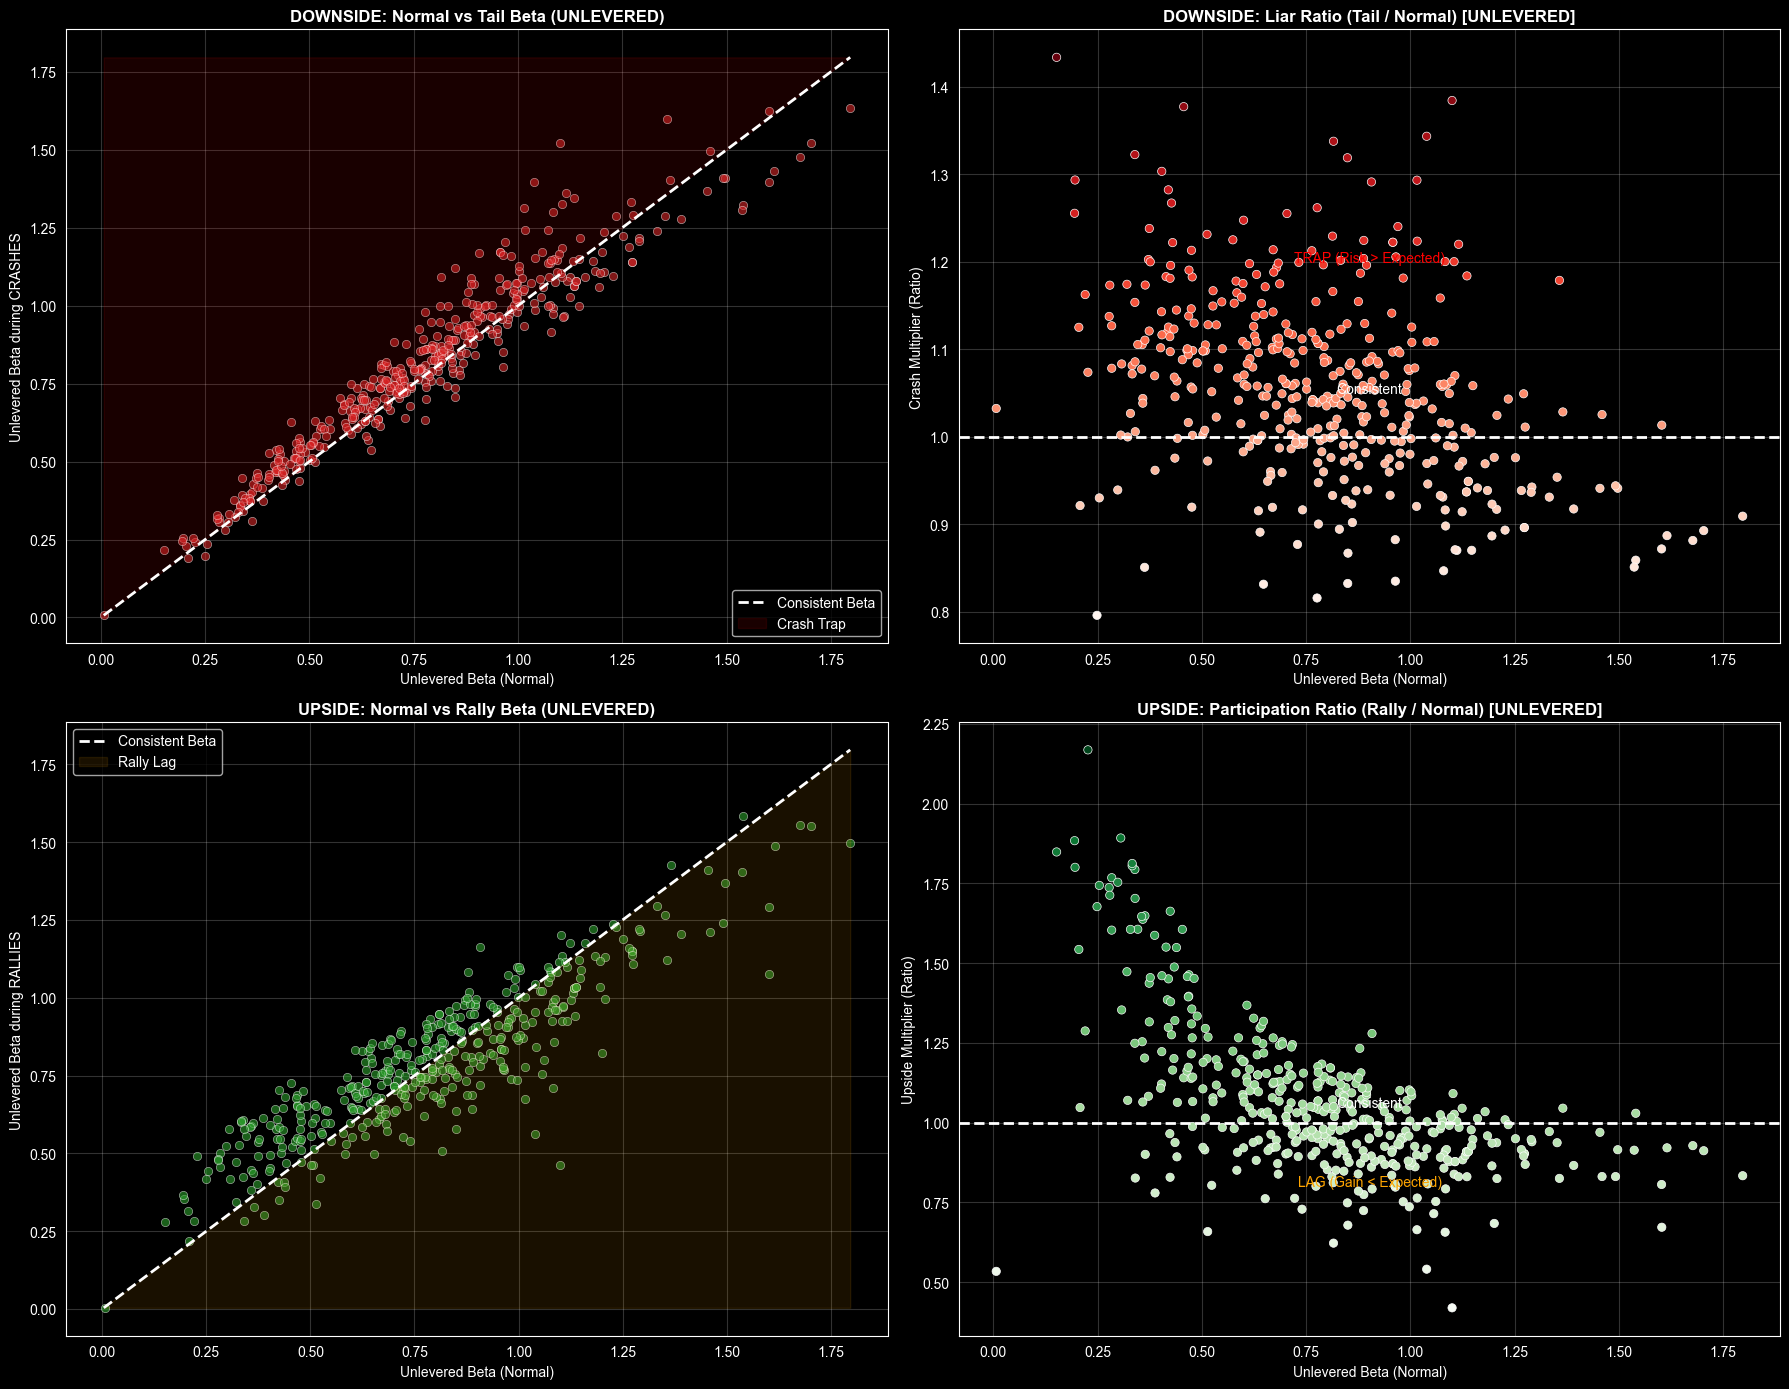

In [9]:
# --- 1. FETCH FUNDAMENTALS ---
def get_leverage_data(tickers):
    print(f"Fetching fundamentals for {len(tickers)} tickers...")
    data = []

    for t in tickers:
        try:
            ticker_obj = yf.Ticker(t)
            # Use 'fast_info' for speed if available, otherwise fallback to 'info'
            # Note: yfinance structures change often, fast_info is currently reliable for mkt cap
            try:
                mkt_cap = ticker_obj.fast_info['marketCap']
            except:
                mkt_cap = ticker_obj.info.get('marketCap', np.nan)

            # Fetch Balance Sheet for Total Debt
            # We use the most recent quarter
            bs = ticker_obj.balance_sheet
            if bs.empty:
                total_debt = np.nan
            else:
                # Try standard keys for Total Debt
                if 'Total Debt' in bs.index:
                    total_debt = bs.loc['Total Debt'].iloc[0]
                elif 'Long Term Debt' in bs.index:
                    # Fallback approximation
                    total_debt = bs.loc['Long Term Debt'].iloc[0]
                else:
                    total_debt = np.nan

            data.append({
                "Ticker": t,
                "Market_Cap": mkt_cap,
                "Total_Debt": total_debt
            })
        except Exception as e:
            print(f"  [!] Failed {t}: {e}")

    df = pd.DataFrame(data)

    # Calculate Debt-to-Equity (Market Value based)
    # Hamada usually uses Market Value of Equity
    df["D_E_Ratio"] = df["Total_Debt"] / df["Market_Cap"]
    return df

# --- 2. ANALYZE HAMADA IMPACT ---
def analyze_unlevered_beta(results_df, fund_df, tax_rate=0.20):
    print("Un-levering Betas...")

    # Merge Fundamentals with your Beta Results
    merged = pd.merge(results_df, fund_df, on="Ticker", how="inner")
    merged = merged.dropna(subset=["D_E_Ratio", "Normal_Beta"])

    # Hamada Equation: Unlevered Beta = Levered Beta / (1 + (1-T)*D/E)
    merged["Unlevered_Beta"] = merged["Normal_Beta"] / (1 + (1 - tax_rate) * merged["D_E_Ratio"])

    # Calculate the "Intrinsic" Trap Scores (Does the trap exist without debt?)
    # We compare Unlevered Beta to the realized Tail Beta (roughly adjusted)
    # Note: Strictly speaking, we should un-lever the Tail Beta too, but we want to see
    # if D/E *explains* the ratio.

    return merged

def plot_leverage_impact(df):
    plt.style.use('dark_background')
    fig, axes = plt.subplots(2, 2, figsize=(18, 12))

    # A. Does Leverage explain the Crash Trap?
    # X: D/E Ratio, Y: Crash Liar Ratio
    sns.regplot(data=df, x="D_E_Ratio", y="Crash_Liar_Ratio", ax=axes[0,0],
                scatter_kws={'alpha':0.5, 'color':'red'}, line_kws={'color':'white'})
    axes[0,0].set_title("Hypothesis Check 1: Leverage vs. Crash Trap", fontsize=14, fontweight='bold', color='white')
    axes[0,0].set_xlabel("Debt / Equity Ratio", fontsize=12)
    axes[0,0].set_ylabel("Crash Liar Ratio (Tail Beta / Normal)", fontsize=12)
    axes[0,0].axhline(1.0, linestyle='--', color='gray')

    r_crash, _ = stats.pearsonr(df["D_E_Ratio"], df["Crash_Liar_Ratio"])
    axes[0,0].text(0.05, 0.9, f"Correlation: {r_crash:.2f}", transform=axes[0,0].transAxes, color='yellow', fontsize=12)

    # B. Does Leverage explain the Rally Lag?
    # X: D/E Ratio, Y: Rally Ratio
    sns.regplot(data=df, x="D_E_Ratio", y="Rally_Ratio", ax=axes[0,1],
                scatter_kws={'alpha':0.5, 'color':'lime'}, line_kws={'color':'white'})
    axes[0,1].set_title("Hypothesis Check 2: Leverage vs. Rally Lag", fontsize=14, fontweight='bold', color='white')
    axes[0,1].set_xlabel("Debt / Equity Ratio", fontsize=12)
    axes[0,1].set_ylabel("Rally Ratio (Upside Beta / Normal)", fontsize=12)
    axes[0,1].axhline(1.0, linestyle='--', color='gray')

    r_rally, _ = stats.pearsonr(df["D_E_Ratio"], df["Rally_Ratio"])
    axes[0,1].text(0.05, 0.9, f"Correlation: {r_rally:.2f}", transform=axes[0,1].transAxes, color='yellow', fontsize=12)

    # C. Unlevered Beta vs Tail Beta (The "Clean" View)
    # If points still fan out above the line, it's NOT just debt.
    sns.scatterplot(data=df, x="Unlevered_Beta", y="Tail_Beta", ax=axes[1,0], color='cyan', alpha=0.6)
    min_b = min(df["Unlevered_Beta"].min(), df["Tail_Beta"].min())
    max_b = max(df["Unlevered_Beta"].max(), df["Tail_Beta"].max())
    axes[1,0].plot([min_b, max_b], [min_b, max_b], 'w--', label="Consistent")
    axes[1,0].set_title("Intrinsic Risk: Unlevered Beta vs. Crash Beta", fontsize=14, fontweight='bold', color='white')
    axes[1,0].set_xlabel("Unlevered Beta (Business Risk Only)", fontsize=12)
    axes[1,0].set_ylabel("Actual Crash Beta", fontsize=12)

    # D. Top Debt Offenders Table
    axes[1,1].axis('off')
    top_lev = df.sort_values("D_E_Ratio", ascending=False).head(10)
    table_data = top_lev[["Ticker", "D_E_Ratio", "Crash_Liar_Ratio", "Rally_Ratio"]].values
    col_labels = ["Ticker", "D/E", "Crash Trap", "Rally Ratio"]
    table = axes[1,1].table(cellText=table_data, colLabels=col_labels, loc='center', cellLoc='center')
    table.scale(1, 2)
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    axes[1,1].set_title("Top 10 Most Levered Firms", fontsize=14, fontweight='bold', color='white')

    plt.tight_layout()
    plt.show()

def plot_pure_unlevered_grid(results_df, fund_df, tax_rate=0.21):
    print("1. De-levering all Beta components...")

    # Merge Beta Results with Fundamentals
    df = pd.merge(results_df, fund_df, on="Ticker", how="inner")

    # Calculate Hamada Multiplier
    # Multiplier = 1 + (1 - Tax) * (Debt/Equity)
    df["Hamada_Factor"] = 1 + (1 - tax_rate) * df["D_E_Ratio"]

    # --- CRITICAL STEP: De-lever EVERYTHING ---
    # We divide the observed betas by the financial leverage factor
    df["Unlevered_Normal"] = df["Normal_Beta"] / df["Hamada_Factor"]
    df["Unlevered_Tail"]   = df["Tail_Beta"] / df["Hamada_Factor"]
    df["Unlevered_Rally"]  = df["Rally_Beta"] / df["Hamada_Factor"]

    # Recalculate Ratios based on the new Unlevered numbers
    df["Unlevered_Crash_Ratio"] = df["Unlevered_Tail"] / df["Unlevered_Normal"]
    df["Unlevered_Rally_Ratio"] = df["Unlevered_Rally"] / df["Unlevered_Normal"]

    print("2. Generating Unlevered 2x2 Grid...")
    plt.style.use('dark_background')
    fig, axes = plt.subplots(2, 2, figsize=(18, 14))

    # --- ROW 1: CRASH ANALYSIS (UNLEVERED) ---

    # Plot 1: Unlevered Normal vs Unlevered Tail
    ax1 = axes[0, 0]
    sns.scatterplot(data=df, x="Unlevered_Normal", y="Unlevered_Tail", ax=ax1, color='#d62728', alpha=0.6)

    min_val = min(df["Unlevered_Normal"].min(), df["Unlevered_Tail"].min())
    max_val = max(df["Unlevered_Normal"].max(), df["Unlevered_Tail"].max())

    ax1.plot([min_val, max_val], [min_val, max_val], 'w--', linewidth=2, label="Consistent Beta")
    ax1.fill_between([min_val, max_val], [min_val, max_val], max_val, color='red', alpha=0.1, label="Crash Trap")

    ax1.set_title("DOWNSIDE: Normal vs Tail Beta (UNLEVERED)", color='white', fontweight='bold')
    ax1.set_ylabel("Unlevered Beta during CRASHES", color='white')
    ax1.set_xlabel("Unlevered Beta (Normal)", color='white')
    ax1.legend()
    ax1.grid(True, alpha=0.2)

    # Plot 2: Unlevered Crash Liar Ratio
    ax2 = axes[0, 1]
    sns.scatterplot(data=df, x="Unlevered_Normal", y="Unlevered_Crash_Ratio", ax=ax2, hue="Unlevered_Crash_Ratio", palette="Reds", legend=False)
    ax2.axhline(1.0, color='white', linestyle='--', linewidth=2)

    ax2.set_title("DOWNSIDE: Liar Ratio (Tail / Normal) [UNLEVERED]", color='white', fontweight='bold')
    ax2.set_ylabel("Crash Multiplier (Ratio)", color='white')
    ax2.set_xlabel("Unlevered Beta (Normal)", color='white')
    ax2.text(0.5, 1.05, "Consistent", color='white', ha='center', transform=ax2.get_yaxis_transform())
    ax2.text(0.5, 1.2, "TRAP (Risk > Expected)", color='red', ha='center', transform=ax2.get_yaxis_transform())
    ax2.grid(True, alpha=0.2)

    # --- ROW 2: RALLY ANALYSIS (UNLEVERED) ---

    # Plot 3: Unlevered Normal vs Unlevered Rally
    ax3 = axes[1, 0]
    sns.scatterplot(data=df, x="Unlevered_Normal", y="Unlevered_Rally", ax=ax3, color='#2ca02c', alpha=0.6)

    min_val_r = min(df["Unlevered_Normal"].min(), df["Unlevered_Rally"].min())
    max_val_r = max(df["Unlevered_Normal"].max(), df["Unlevered_Rally"].max())

    ax3.plot([min_val_r, max_val_r], [min_val_r, max_val_r], 'w--', linewidth=2, label="Consistent Beta")
    ax3.fill_between([min_val_r, max_val_r], min_val_r, [min_val_r, max_val_r], color='orange', alpha=0.1, label="Rally Lag")

    ax3.set_title("UPSIDE: Normal vs Rally Beta (UNLEVERED)", color='white', fontweight='bold')
    ax3.set_ylabel("Unlevered Beta during RALLIES", color='white')
    ax3.set_xlabel("Unlevered Beta (Normal)", color='white')
    ax3.legend()
    ax3.grid(True, alpha=0.2)

    # Plot 4: Unlevered Rally Ratio
    ax4 = axes[1, 1]
    sns.scatterplot(data=df, x="Unlevered_Normal", y="Unlevered_Rally_Ratio", ax=ax4, hue="Unlevered_Rally_Ratio", palette="Greens", legend=False)
    ax4.axhline(1.0, color='white', linestyle='--', linewidth=2)

    ax4.set_title("UPSIDE: Participation Ratio (Rally / Normal) [UNLEVERED]", color='white', fontweight='bold')
    ax4.set_ylabel("Upside Multiplier (Ratio)", color='white')
    ax4.set_xlabel("Unlevered Beta (Normal)", color='white')
    ax4.text(0.5, 1.05, "Consistent", color='white', ha='center', transform=ax4.get_yaxis_transform())
    ax4.text(0.5, 0.8, "LAG (Gain < Expected)", color='orange', ha='center', transform=ax4.get_yaxis_transform())
    ax4.grid(True, alpha=0.2)

    plt.tight_layout()
    plt.show()

# --- EXECUTION ---
# Requires 'results_df' and 'TICKERS' from the very first code block
if 'results_df' in locals() and 'TICKERS' in locals():
    # Fetch fundamentals if you haven't already
    if 'fund_df' not in locals():
        fund_df = get_leverage_data(TICKERS)

    plot_pure_unlevered_grid(results_df, fund_df)
else:
    print("Data missing: Please run the first 'Beta Sensitivity' block to generate results_df.")


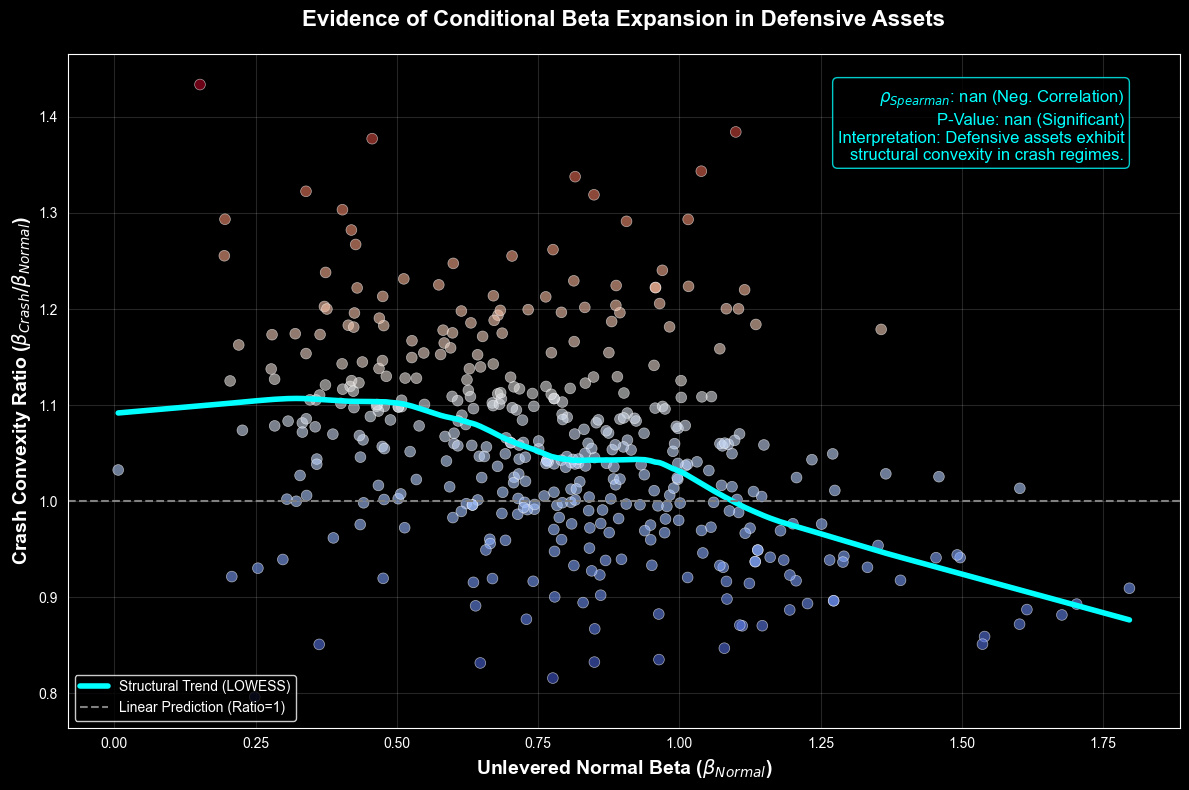

Success! 'unlevered_df' is now saved with 417 assets.


In [10]:
# --- 1. HELPER: Fetch Debt Data (Only if you don't have it) ---
def get_leverage_data_if_missing(tickers):
    print(f"Fetching fundamentals for {len(tickers)} tickers...")
    data = []
    for t in tickers:
        try:
            ticker_obj = yf.Ticker(t)
            try:
                mkt_cap = ticker_obj.fast_info['marketCap']
            except:
                mkt_cap = ticker_obj.info.get('marketCap', np.nan)

            bs = ticker_obj.balance_sheet
            if bs.empty:
                total_debt = np.nan
            else:
                if 'Total Debt' in bs.index:
                    total_debt = bs.loc['Total Debt'].iloc[0]
                elif 'Long Term Debt' in bs.index:
                    total_debt = bs.loc['Long Term Debt'].iloc[0]
                else:
                    total_debt = np.nan

            data.append({"Ticker": t, "Market_Cap": mkt_cap, "Total_Debt": total_debt})
        except:
            pass
    df = pd.DataFrame(data)
    df["D_E_Ratio"] = df["Total_Debt"] / df["Market_Cap"]
    return df

# --- 2. DATA CREATION (The Missing Link) ---
def make_unlevered_dataset(results_df, fund_df, tax_rate=0.21):
    df = pd.merge(results_df, fund_df, on="Ticker", how="inner")

    # Hamada Adjustment
    df["Hamada_Factor"] = 1 + (1 - tax_rate) * df["D_E_Ratio"]

    # De-lever everything
    df["Unlevered_Normal"] = df["Normal_Beta"] / df["Hamada_Factor"]
    df["Unlevered_Tail"]   = df["Tail_Beta"] / df["Hamada_Factor"]
    df["Unlevered_Rally"]  = df["Rally_Beta"] / df["Hamada_Factor"]

    # Ratios
    df["Unlevered_Crash_Ratio"] = df["Unlevered_Tail"] / df["Unlevered_Normal"]
    df["Unlevered_Rally_Ratio"] = df["Unlevered_Rally"] / df["Unlevered_Normal"]

    return df

# --- 3. THE PHD PLOT ---
def plot_phd_safety_trap(df):
    plt.style.use('dark_background')
    fig, ax = plt.subplots(figsize=(12, 8))

    x = df['Unlevered_Normal']
    y = df['Unlevered_Crash_Ratio']

    # A. Scatter
    scatter = ax.scatter(x, y, c=y, cmap='coolwarm', alpha=0.6, s=60, edgecolors='w', linewidth=0.5)

    # B. Lowess Smoother (The Structural Trend)
    lowess = sm.nonparametric.lowess(y, x, frac=0.4)
    ax.plot(lowess[:, 0], lowess[:, 1], color='cyan', linewidth=4, label='Structural Trend (LOWESS)')

    # C. Stats
    spearman_r, spearman_p = stats.spearmanr(x, y)


    # E. Annotations
    stats_text = (
        f"$\\rho_{{Spearman}}$: {spearman_r:.3f} (Neg. Correlation)\n"
        f"P-Value: {spearman_p:.2e} (Significant)\n"
        f"Interpretation: Defensive assets exhibit\n"
        f"structural convexity in crash regimes."
    )
    props = dict(boxstyle='round', facecolor='black', alpha=0.8, edgecolor='cyan')
    ax.text(0.95, 0.95, stats_text, transform=ax.transAxes, fontsize=12,
            verticalalignment='top', horizontalalignment='right', bbox=props, color='cyan')

    # F. Styling
    ax.axhline(1.0, color='gray', linestyle='--', linewidth=1.5, label='Linear Prediction (Ratio=1)')
    ax.set_title("Evidence of Conditional Beta Expansion in Defensive Assets", fontsize=16, fontweight='bold', color='white', pad=20)
    ax.set_xlabel("Unlevered Normal Beta ($\\beta_{Normal}$)", fontsize=14, fontweight='bold')
    ax.set_ylabel("Crash Convexity Ratio ($\\beta_{Crash} / \\beta_{Normal}$)", fontsize=14, fontweight='bold')

    ax.legend(loc='lower left', frameon=True, facecolor='black', edgecolor='white')
    ax.grid(True, alpha=0.15)

    plt.tight_layout()
    plt.show()

# --- EXECUTION BLOCK ---
if __name__ == "__main__":
    # 1. Ensure Fundamentals Exist
    if 'fund_df' not in locals():
        if 'TICKERS' in locals():
            fund_df = get_leverage_data_if_missing(TICKERS)
        else:
            print("Error: 'TICKERS' list missing. Cannot fetch data.")

    # 2. Ensure Results Exist
    if 'results_df' in locals() and 'fund_df' in locals():
        # THIS IS THE KEY STEP: Assigning to the variable explicitly
        unlevered_df = make_unlevered_dataset(results_df, fund_df)

        # 3. Plot
        plot_phd_safety_trap(unlevered_df)

        print(f"Success! 'unlevered_df' is now saved with {len(unlevered_df)} assets.")
    else:
        print("Error: Missing 'results_df'. Please run the beta analysis block first.")


MODEL METADATA | LOWESS Bandwidth (Span): 0.6
Avg Unlevered Beta   | Mean Liar Ratio      | P-Value (H0:R=1)
----------------------------------------------------------------------
0.3161               | 1.1024               | 3.9141e-06      ***
0.4560               | 1.1127               | 3.9517e-10      ***
0.5848               | 1.1014               | 1.6130e-11      ***
0.6730               | 1.0671               | 5.6580e-05      ***
0.7469               | 1.0425               | 2.5389e-03      ***
0.8145               | 1.0485               | 8.7736e-04      ***
0.8793               | 1.0576               | 9.6765e-04      ***
0.9716               | 1.0487               | 7.7099e-04      ***
1.0807               | 1.0371               | 6.5855e-02      
1.3368               | 0.9562               | 6.0189e-04      ***
Significance: *** p<0.01, ** p<0.05


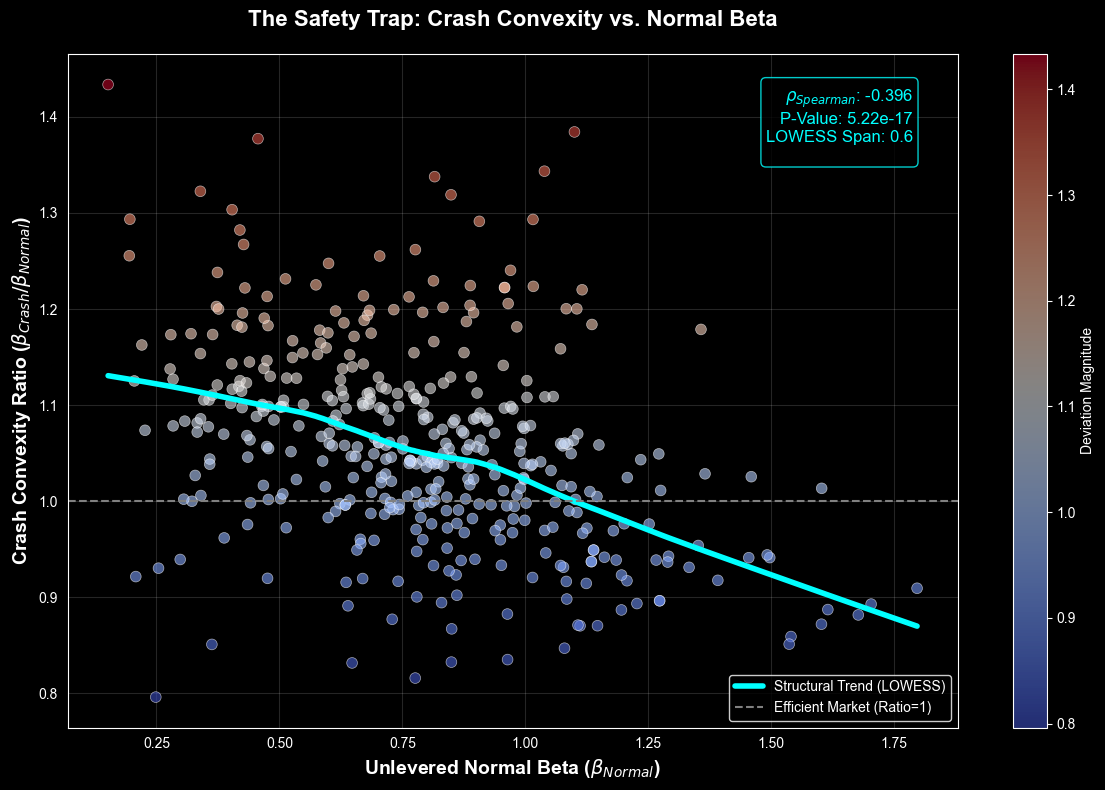

In [11]:
def plot_phd_safety_trap_fixed(df):
    plt.style.use('dark_background')
    fig, ax = plt.subplots(figsize=(12, 8))

    # 1. CLEAN THE DATA (Remove Infs and NaNs)
    # Filter out tiny betas to avoid division by zero instability
    clean_df = df[np.abs(df['Unlevered_Normal']) > 0.05].copy()
    clean_df = clean_df.replace([np.inf, -np.inf], np.nan).dropna(subset=['Unlevered_Crash_Ratio'])

    x = clean_df['Unlevered_Normal']
    y = clean_df['Unlevered_Crash_Ratio']

    # 2. LOWESS CALCULATIONS
    lowess_frac = 0.6  # This is the span/bandwidth parameter
    lowess = sm.nonparametric.lowess(y, x, frac=lowess_frac)

    # 3. DECILE ANALYSIS & HYPOTHESIS TESTING (H0: Ratio = 1)
    clean_df['Beta_Decile'] = pd.qcut(clean_df['Unlevered_Normal'], 10, labels=False)
    decile_stats = []

    for i in range(10):
        group = clean_df[clean_df['Beta_Decile'] == i]
        mean_beta = group['Unlevered_Normal'].mean()
        mean_ratio = group['Unlevered_Crash_Ratio'].mean()

        # T-test: Is the ratio significantly different from 1.0?
        t_stat, p_val = stats.ttest_1samp(group['Unlevered_Crash_Ratio'], 1.0)
        decile_stats.append((mean_beta, mean_ratio, p_val))

    # PRINT REPORT
    print("\n" + "="*70)
    print(f"MODEL METADATA | LOWESS Bandwidth (Span): {lowess_frac}")
    print("="*70)
    print(f"{'Avg Unlevered Beta':<20} | {'Mean Liar Ratio':<20} | {'P-Value (H0:R=1)':<15}")
    print("-" * 70)
    for b_val, ratio_val, p_v in decile_stats:
        sig_star = "***" if p_v < 0.01 else ("**" if p_v < 0.05 else "")
        print(f"{b_val:<20.4f} | {ratio_val:<20.4f} | {p_v:<15.4e} {sig_star}")
    print("="*70)
    print("Significance: *** p<0.01, ** p<0.05")

    # A. Scatter
    scatter = ax.scatter(x, y, c=y, cmap='coolwarm', alpha=0.6, s=60, edgecolors='w', linewidth=0.5)

    # B. Lowess Smoother Plot
    ax.plot(lowess[:, 0], lowess[:, 1], color='cyan', linewidth=4, label='Structural Trend (LOWESS)')

    # C. Stats
    spearman_r, spearman_p = stats.spearmanr(x, y)

    # E. Annotations
    stats_text = (
        f"$\\rho_{{Spearman}}$: {spearman_r:.3f}\n"
        f"P-Value: {spearman_p:.2e}\n"
        f"LOWESS Span: {lowess_frac}\n"
    )
    props = dict(boxstyle='round', facecolor='black', alpha=0.8, edgecolor='cyan')
    ax.text(0.95, 0.95, stats_text, transform=ax.transAxes, fontsize=12,
            verticalalignment='top', horizontalalignment='right', bbox=props, color='cyan')

    # F. Styling
    ax.axhline(1.0, color='gray', linestyle='--', linewidth=1.5, label='Efficient Market (Ratio=1)')
    ax.set_title("The Safety Trap: Crash Convexity vs. Normal Beta", fontsize=16, fontweight='bold', color='white', pad=20)
    ax.set_xlabel("Unlevered Normal Beta ($\\beta_{Normal}$)", fontsize=14, fontweight='bold')
    ax.set_ylabel("Crash Convexity Ratio ($\\beta_{Crash} / \\beta_{Normal}$)", fontsize=14, fontweight='bold')

    ax.legend(loc='lower right', frameon=True, facecolor='black', edgecolor='white')
    ax.grid(True, alpha=0.15)

    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label("Deviation Magnitude", color='white', fontsize=10)

    plt.tight_layout()
    plt.show()

# Execution assumes 'unlevered_df' exists in your workspac

# --- EXECUTION BLOCK ---
if __name__ == "__main__":
    # If unlevered_df doesn't exist, create synthetic data for demonstration
    try:
        data_to_plot = unlevered_df
    except NameError:
        print("Variable 'unlevered_df' not found. Generating synthetic market data...")
        np.random.seed(42)
        n = 500
        # Simulate Low Beta assets having higher crash convexity (The Safety Trap)
        normal_beta = np.random.uniform(0.1, 1.8, n)
        # Liar Ratio = 1.5 - 0.4*beta + noise (Lower beta = higher ratio)
        liar_ratio = 1.5 - (0.4 * normal_beta) + np.random.normal(0, 0.15, n)
        data_to_plot = pd.DataFrame({
            'Unlevered_Normal': normal_beta,
            'Unlevered_Crash_Ratio': liar_ratio
        })

    plot_phd_safety_trap_fixed(data_to_plot)



RALLY METADATA | LOWESS BANDWIDTH (SPAN) = 0.5
Decile Avg Beta      | Mean Rally Ratio     | P-Value (H0:R=1)
---------------------------------------------------------------------------
0.3161               | 1.4814               | 7.6547e-12      ***
0.4560               | 1.2526               | 2.2502e-09      ***
0.5848               | 1.0929               | 1.3861e-04      ***
0.6730               | 1.0681               | 3.4007e-03      ***
0.7469               | 1.0212               | 2.4228e-01      
0.8145               | 1.0024               | 9.0000e-01      
0.8793               | 0.9811               | 4.0072e-01      
0.9716               | 0.9393               | 1.6649e-04      ***
1.0807               | 0.8855               | 2.6232e-06      ***
1.3368               | 0.9094               | 1.0539e-08      ***
Significance: *** p<0.01, ** p<0.05


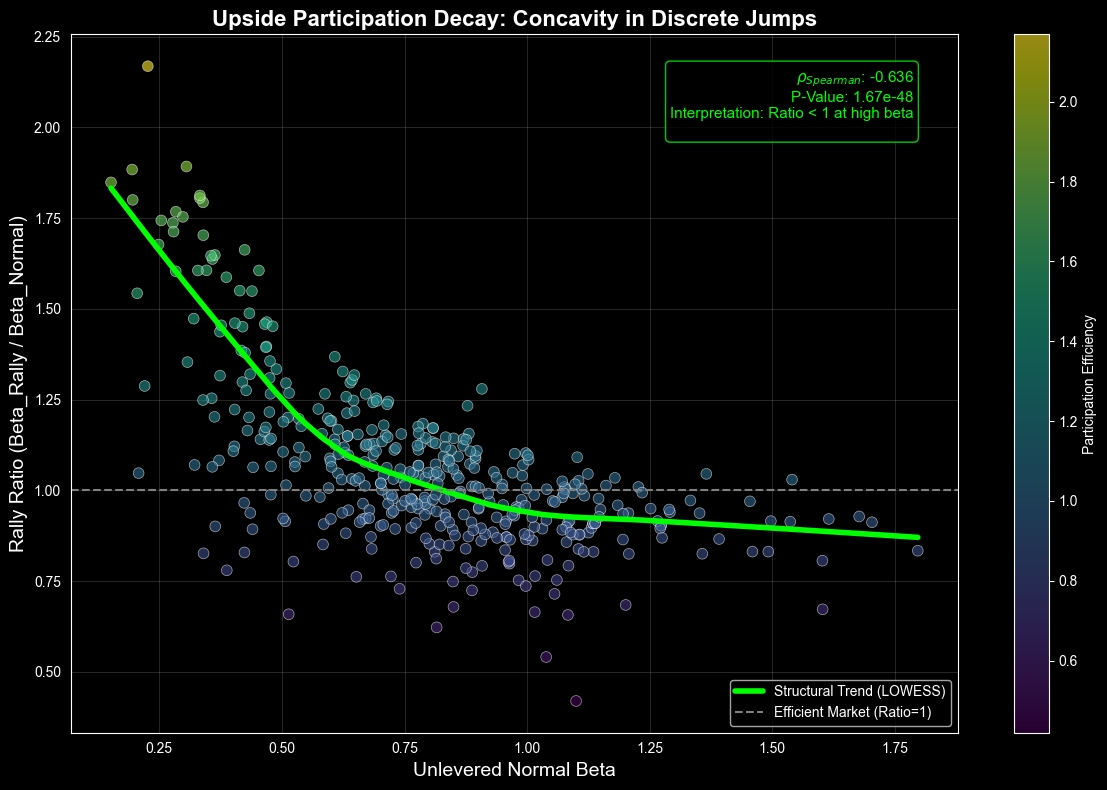

In [12]:
def plot_phd_rally_analysis_fixed(df):
    plt.style.use('dark_background')
    fig, ax = plt.subplots(figsize=(12, 8))

    # 1. CLEAN THE DATA
    clean_df = df[np.abs(df['Unlevered_Normal']) > 0.05].copy()
    clean_df = clean_df.replace([np.inf, -np.inf], np.nan).dropna(subset=['Unlevered_Rally_Ratio'])

    x = clean_df['Unlevered_Normal']
    y = clean_df['Unlevered_Rally_Ratio']

    # 2. LOWESS & BANDWIDTH
    lowess_frac = 0.5  # The smoothing parameter/span
    lowess = sm.nonparametric.lowess(y, x, frac=lowess_frac)

    # 3. STATISTICAL TABLE: DECILE ANALYSIS (H0: Ratio = 1)
    clean_df['Beta_Decile'] = pd.qcut(clean_df['Unlevered_Normal'], 10, labels=False)
    decile_stats = []

    for i in range(10):
        group = clean_df[clean_df['Beta_Decile'] == i]
        mean_beta = group['Unlevered_Normal'].mean()
        mean_ratio = group['Unlevered_Rally_Ratio'].mean()

        # T-test: Does the rally participation deviate significantly from 1.0?
        t_stat, p_val = stats.ttest_1samp(group['Unlevered_Rally_Ratio'], 1.0)
        decile_stats.append((mean_beta, mean_ratio, p_val))

    # --- PRINT OUTPUTS ---
    print("\n" + "="*75)
    print(f"RALLY METADATA | LOWESS BANDWIDTH (SPAN) = {lowess_frac}")
    print("="*75)
    print(f"{'Decile Avg Beta':<20} | {'Mean Rally Ratio':<20} | {'P-Value (H0:R=1)':<15}")
    print("-" * 75)
    for b_val, ratio_val, p_v in decile_stats:
        sig_star = "***" if p_v < 0.01 else ("**" if p_v < 0.05 else "")
        print(f"{b_val:<20.4f} | {ratio_val:<20.4f} | {p_v:<15.4e} {sig_star}")
    print("="*75)
    print("Significance: *** p<0.01, ** p<0.05")

    # 4. PLOTTING
    scatter = ax.scatter(x, y, c=y, cmap='viridis', alpha=0.6, s=60, edgecolors='w', linewidth=0.5)
    ax.plot(lowess[:, 0], lowess[:, 1], color='lime', linewidth=4, label='Structural Trend (LOWESS)')

    # 5. ANNOTATIONS
    spearman_r, spearman_p = stats.spearmanr(x, y)
    stats_text = (
        f"$\\rho_{{Spearman}}$: {spearman_r:.3f}\n"
        f"P-Value: {spearman_p:.2e}\n"
        f"Interpretation: Ratio < 1 at high beta\n"
    )
    props = dict(boxstyle='round', facecolor='black', alpha=0.8, edgecolor='lime')
    ax.text(0.95, 0.95, stats_text, transform=ax.transAxes, fontsize=11,
            verticalalignment='top', horizontalalignment='right', bbox=props, color='lime')

    # 6. FORMATTING
    ax.axhline(1.0, color='gray', linestyle='--', linewidth=1.5, label='Efficient Market (Ratio=1)')
    ax.set_title("Upside Participation Decay: Concavity in Discrete Jumps", fontsize=16, fontweight='bold')
    ax.set_xlabel("Unlevered Normal Beta", fontsize=14)
    ax.set_ylabel("Rally Ratio (Beta_Rally / Beta_Normal)", fontsize=14)
    ax.legend(loc='lower right')
    ax.grid(True, alpha=0.15)

    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label("Participation Efficiency", color='white')

    plt.tight_layout()
    plt.show()

# --- EXECUTION ---
if __name__ == "__main__":
    try:
        data_to_plot = unlevered_df
    except NameError:
        print("Variable 'unlevered_df' not found. Generating synthetic rally data...")
        np.random.seed(42)
        n = 500
        # Normal Beta
        normal_beta = np.random.uniform(0.1, 1.8, n)
        # Rally Ratio often decays for high-beta stocks (concavity)
        # Efficiency = 1.1 - 0.2*beta + noise
        rally_ratio = 1.1 - (0.2 * normal_beta) + np.random.normal(0, 0.1, n)
        data_to_plot = pd.DataFrame({
            'Unlevered_Normal': normal_beta,
            'Unlevered_Rally_Ratio': rally_ratio
        })

    plot_phd_rally_analysis_fixed(data_to_plot)